# IS403 - Walmart M5: XGBoost with Optuna and Early Stopping

Train one XGBoost family on the audited Level 1 features from notebook 05.
Compare historical inputs, added calendar/events, and added SNAP, with separate
parameter tuning for each group. Use the same dataset and CPU settings as
notebooks 00-06. No extra NPZ input, package installation or Internet is needed
in the standard Kaggle environment.

Only Train and Validation are read. All 28 forecasts are issued from one fixed
origin using the approved target-day lag rule. Optuna and early stopping use
the designated Validation window for selection. Earlier-window evaluation then
refits fixed selected parameters and tree counts without early stopping on
those windows. These are development results, not independent Test results.

In [1]:
from pathlib import Path
from importlib import metadata
from datetime import datetime, timezone
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import json
import platform
import random
import warnings
import xgboost as xgb
import optuna
from optuna.trial import TrialState
from threadpoolctl import threadpool_limits

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = None
OUTPUT_DIR = None
SEED = 42
HORIZON = 28
ORIGINS = (1829, 1857, 1885)
LAGS = (28, 35, 42, 56)
ROLLING_SHIFT = 28
ROLLING_WINDOWS = (7, 28, 56)
FEATURE_GROUPS = ('lags', 'lags_calendar_events', 'lags_calendar_events_snap')
EXOG_COLUMNS = ['wday_iso', 'month', 'event_name_1', 'event_name_2',
                'snap_CA', 'snap_TX', 'snap_WI']
random.seed(SEED)
np.random.seed(SEED)
RUN_STARTED = perf_counter()
SEASON_LENGTH = 7
MA_WINDOWS = (7, 28)
SALES_SCALE = 1000.0
TRIALS_PER_GROUP = 24
STARTUP_TRIALS = 8
MAX_BOOST_ROUNDS = 1200
EARLY_STOPPING_ROUNDS = 40
MODEL_JOBS = 1
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1. Rebuild and verify the shared feature algorithm

The historical sources, train-only vocabulary/scaling checks, warm-up and
10/48/51-column feature groups are unchanged from notebook 05. Trees receive
the raw feature matrix. The constant sales divisor 1000 only changes numerical
units; all forecasts, plotted errors and metrics are restored to original units.

In [2]:
FILENAMES = ('train.csv', 'val.csv')


def find_data_directory(override=None):
    if override is not None:
        selected = Path(override).expanduser().resolve()
        if not all((selected / name).is_file() for name in FILENAMES):
            raise FileNotFoundError(f'Expected train.csv and val.csv in: {selected}')
        return selected

    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if all((directory / name).is_file() for name in FILENAMES):
            candidates.add(directory.resolve())

    root = Path('/kaggle/input')
    if root.is_dir():
        for path in root.rglob('train.csv'):
            if all((path.parent / name).is_file() for name in FILENAMES):
                candidates.add(path.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            'Attach the processed Kaggle dataset containing train.csv and val.csv, '
            'or set DATA_DIR explicitly.'
        )
    if len(candidates) > 1:
        options = '\n'.join(str(path) for path in sorted(candidates))
        raise ValueError(f'Multiple datasets found. Set DATA_DIR explicitly:\n{options}')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'xgboost_output'
)
print(f'Data: {data_dir}')
print(f'Output: {output_dir.resolve()}')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Output: /kaggle/working


In [3]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
NUMERIC_COLUMNS = ['total_sales', 'wday_iso', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']
EVENT_COLUMNS = ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']
REFERENCE_SHA256 = {'train': 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271', 'val': 'fbee2683fca3c5fc731b1d81829a56aa12c71e5b70ad124a1ac01ab3754536b5'}
SPLIT_DAYS = {'train': (1, 1885), 'val': (1886, 1913)}
FIRST_DATE = pd.Timestamp('2011-01-29')


def require(condition, message):
    if not condition:
        raise ValueError(message)


def table_sha256(frame):
    canonical_csv = frame[EXPECTED_COLUMNS].to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()


def validate_split(name, directory):
    path = directory / f'{name}.csv'
    frame = pd.read_csv(path, keep_default_na=False)
    require(list(frame.columns) == EXPECTED_COLUMNS,
            f'{name}: columns or column order differ from the audited dataset.')

    first, last = SPLIT_DAYS[name]
    require(len(frame) == last - first + 1, f'{name}: incorrect row count.')
    require(frame['d'].tolist() == [f'd_{day}' for day in range(first, last + 1)],
            f'{name}: day IDs are missing, duplicated, or out of order.')
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    expected_dates = pd.date_range(FIRST_DATE + pd.Timedelta(days=first - 1),
                                   periods=len(frame), freq='D')
    require(pd.DatetimeIndex(dates).equals(expected_dates),
            f'{name}: dates do not match the fixed chronological split.')
    require(not frame.duplicated(['d']).any() and not dates.duplicated().any(),
            f'{name}: duplicate day or date.')
    frame['date'] = dates.dt.strftime('%Y-%m-%d')

    for column in NUMERIC_COLUMNS:
        values = pd.to_numeric(frame[column], errors='raise')
        require(bool(np.isfinite(values.to_numpy()).all()),
                f'{name}: {column} contains missing or non-finite values.')
        require(bool((values % 1 == 0).all()), f'{name}: {column} must contain integers.')
        frame[column] = values.astype(np.int64)

    require(bool((frame['total_sales'] >= 0).all()), f'{name}: negative sales.')
    require(np.array_equal(frame['wday_iso'], dates.dt.dayofweek + 1),
            f'{name}: incorrect ISO weekday (Monday=1).')
    require(np.array_equal(frame['month'], dates.dt.month), f'{name}: incorrect month.')
    require(np.array_equal(frame['year'], dates.dt.year), f'{name}: incorrect year.')
    require(frame['weekday'].tolist() == dates.dt.day_name().tolist(),
            f'{name}: incorrect weekday names.')
    for column in ['snap_CA', 'snap_TX', 'snap_WI']:
        require(bool(frame[column].isin([0, 1]).all()), f'{name}: {column} is not binary.')
    for column in EVENT_COLUMNS:
        require(bool(frame[column].map(lambda value: isinstance(value, str)
                     and bool(value.strip())).all()),
                f'{name}: empty event labels; expected the literal string None.')

    fingerprint = table_sha256(frame)
    require(fingerprint == REFERENCE_SHA256[name],
            f'{name}: table values differ from the audited handoff. '
            'Use the audited original processed CSV files.')
    inventory = {
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'first_day': frame['d'].iloc[0],
        'last_day': frame['d'].iloc[-1],
        'first_date': frame['date'].iloc[0],
        'last_date': frame['date'].iloc[-1],
        'table_sha256': fingerprint,
        'matches_audited_handoff': True,
    }
    return frame, inventory

In [4]:
frames = {}
input_inventory = []
for split in SPLIT_DAYS:
    frames[split], record = validate_split(split, data_dir)
    input_inventory.append(record)

development = pd.concat([frames['train'], frames['val']], ignore_index=True)
require(len(development) == 1913, 'Expected exactly 1,913 development days.')
require(development['d'].tolist() == [f'd_{day}' for day in range(1, 1914)],
        'Development data must be consecutive and end at d_1913.')
development['date'] = pd.to_datetime(development['date'])

fold_plan = pd.DataFrame([
    {
        'fold': fold,
        'origin_day': f'd_{origin}',
        'origin_date': development.iloc[origin - 1]['date'].strftime('%Y-%m-%d'),
        'history_rows': origin,
        'forecast_start': development.iloc[origin]['date'].strftime('%Y-%m-%d'),
        'forecast_end': development.iloc[origin + HORIZON - 1]['date'].strftime('%Y-%m-%d'),
    }
    for fold, origin in enumerate(ORIGINS, start=1)
])
print(pd.DataFrame(input_inventory)[['file', 'rows', 'columns',
                                    'matches_audited_handoff']].to_string(index=False))
print(fold_plan.to_string(index=False))
print('PASS: development data verified; test.csv has not been read.')

     file  rows  columns  matches_audited_handoff
train.csv  1885       14                     True
  val.csv    28       14                     True
 fold origin_day origin_date  history_rows forecast_start forecast_end
    1     d_1829  2016-01-31          1829     2016-02-01   2016-02-28
    2     d_1857  2016-02-28          1857     2016-02-29   2016-03-27
    3     d_1885  2016-03-27          1885     2016-03-28   2016-04-24
PASS: development data verified; test.csv has not been read.


In [5]:
HISTORY_RULES = {}
for lag in LAGS:
    HISTORY_RULES[f'lag_{lag}'] = {'kind': 'lag', 'lag': lag,
                                  'minimum_offset': lag, 'maximum_offset': lag}
for window in ROLLING_WINDOWS:
    for statistic in ('mean', 'std'):
        HISTORY_RULES[f'rolling_{statistic}_{window}_shift_{ROLLING_SHIFT}'] = {
            'kind': 'rolling_' + statistic, 'window': window,
            'minimum_offset': ROLLING_SHIFT,
            'maximum_offset': ROLLING_SHIFT + window - 1}
HISTORY_COLUMNS = list(HISTORY_RULES)
CALENDAR_COLUMNS = [f'weekday_{day}' for day in range(2, 8)] + ['month_sin', 'month_cos']
SNAP_COLUMNS = ['snap_CA', 'snap_TX', 'snap_WI']
WARMUP = max(rule['maximum_offset'] for rule in HISTORY_RULES.values())
require(WARMUP == 83, 'Unexpected historical warm-up.')
require(all(rule['minimum_offset'] >= HORIZON for rule in HISTORY_RULES.values()),
        'A historical feature can access sales after the forecast origin.')


def historical_features(sales):
    values = pd.Series(np.asarray(sales, dtype=np.float64))
    result = pd.DataFrame(index=values.index)
    for lag in LAGS:
        result[f'lag_{lag}'] = values.shift(lag)
    shifted = values.shift(ROLLING_SHIFT)
    for window in ROLLING_WINDOWS:
        rolling = shifted.rolling(window, min_periods=window)
        result[f'rolling_mean_{window}_shift_{ROLLING_SHIFT}'] = rolling.mean()
        result[f'rolling_std_{window}_shift_{ROLLING_SHIFT}'] = rolling.std(ddof=0)
    require(list(result.columns) == HISTORY_COLUMNS, 'Historical column order changed.')
    return result


def event_names(frame):
    return sorted({str(v) for column in ['event_name_1', 'event_name_2']
                   for v in frame[column] if str(v) != 'None'})


def known_calendar_features(frame, vocabulary):
    require(list(frame.columns) == EXOG_COLUMNS,
            'Calendar feature input must exclude targets and unapproved columns.')
    result = pd.DataFrame(index=frame.index)
    for day in range(2, 8):
        result[f'weekday_{day}'] = (frame['wday_iso'].to_numpy() == day).astype(float)
    angle = 2 * np.pi * (frame['month'].to_numpy(dtype=float) - 1) / 12
    result['month_sin'], result['month_cos'] = np.sin(angle), np.cos(angle)
    for index, name in enumerate(vocabulary):
        result[f'event_{index:02d}'] = (
            frame['event_name_1'].eq(name) | frame['event_name_2'].eq(name)).astype(float)
    for column in SNAP_COLUMNS:
        result[column] = frame[column].to_numpy(dtype=float)
    return result.reset_index(drop=True)


def build_feature_bundle(history, known_future):
    require(len(known_future) == HORIZON, 'Expected 28 known future calendar rows.')
    require(list(known_future.columns) == EXOG_COLUMNS,
            'Do not pass future actual sales into the feature builder.')
    origin = len(history)
    require(origin > WARMUP, 'Insufficient history.')
    y = history['total_sales'].to_numpy(dtype=float)
    usable = np.arange(WARMUP, origin)
    train_known = history.iloc[usable][EXOG_COLUMNS].reset_index(drop=True)
    vocabulary = event_names(train_known)
    train_h = historical_features(y).iloc[usable].reset_index(drop=True)
    # Missing placeholders deliberately prevent access to any forecast-window actual.
    future_h = historical_features(np.r_[y, np.full(HORIZON, np.nan)]).iloc[origin:]
    future_h = future_h.reset_index(drop=True)
    train_c = known_calendar_features(train_known, vocabulary)
    future_c = known_calendar_features(known_future.reset_index(drop=True), vocabulary)
    X_train = pd.concat([train_h, train_c], axis=1)
    X_future = pd.concat([future_h, future_c], axis=1)
    require(np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_future.to_numpy()).all(),
            'Feature matrices contain missing or non-finite values.')
    require(list(X_train.columns) == list(X_future.columns), 'Feature schemas differ.')
    means = X_train.mean(axis=0).to_numpy(dtype=float)
    raw_stds = X_train.std(axis=0, ddof=0).to_numpy(dtype=float)
    scales = np.where(raw_stds > 0, raw_stds, 1.0)
    groups = {
        'lags': HISTORY_COLUMNS,
        'lags_calendar_events': [c for c in X_train.columns if c not in SNAP_COLUMNS],
        'lags_calendar_events_snap': list(X_train.columns),
    }
    schema = {
        'origin_day': origin, 'warmup_rows': WARMUP,
        'training_rows': len(usable), 'forecast_rows': HORIZON,
        'training_first_day': WARMUP + 1, 'training_last_day': origin,
        'columns': list(X_train.columns), 'groups': groups,
        'event_vocabulary': vocabulary,
        'event_column_mapping': {f'event_{i:02d}': name for i, name in enumerate(vocabulary)},
        'unseen_future_events': sorted(set(event_names(known_future)) - set(vocabulary)),
        'scaler_fit_rows': len(X_train), 'scaler_ddof': 0,
        'scaler_mean': means.tolist(), 'scaler_scale': scales.tolist(),
        'constant_training_columns': [c for c, std in zip(X_train.columns, raw_stds) if std == 0],
        'target_transform': 'none; original sales units',
    }
    return {'X_train': X_train.to_numpy(dtype=float),
            'X_future': X_future.to_numpy(dtype=float),
            'X_train_scaled': (X_train.to_numpy(dtype=float) - means) / scales,
            'X_future_scaled': (X_future.to_numpy(dtype=float) - means) / scales,
            'y_train': y[usable].copy(),
            'train_day': usable + 1,
            'future_day': np.arange(origin + 1, origin + HORIZON + 1),
            'schema': schema}

In [6]:
bundles = {}
fold_summary_rows = []
dictionary_rows = []
for fold, origin in enumerate(ORIGINS, start=1):
    history = development.iloc[:origin].copy()
    future_known = development.iloc[origin:origin + HORIZON][EXOG_COLUMNS].copy()
    bundle = build_feature_bundle(history, future_known)
    bundle['y_future'] = development.iloc[origin:origin + HORIZON]['total_sales'].to_numpy(dtype=float)
    schema = bundle['schema']
    bundles[fold] = bundle
    fold_summary_rows.append({
        'fold': fold, 'origin_day': origin, 'training_rows': schema['training_rows'],
        'training_first_day': schema['training_first_day'], 'training_last_day': origin,
        'forecast_rows': HORIZON, 'forecast_first_day': origin + 1,
        'forecast_last_day': origin + HORIZON,
        'lags_features': len(schema['groups']['lags']),
        'calendar_event_features': len(schema['groups']['lags_calendar_events']),
        'full_features': len(schema['columns']),
        'unseen_event_count': len(schema['unseen_future_events']),
        'scaler_fit_rows': schema['scaler_fit_rows'],
    })
    for index, name in enumerate(schema['columns']):
        rule = HISTORY_RULES.get(name, {})
        dictionary_rows.append({
            'fold': fold, 'feature': name,
            'family': ('historical_sales' if name in HISTORY_RULES else
                       'SNAP' if name in SNAP_COLUMNS else
                       'event' if name in schema['event_column_mapping'] else 'calendar'),
            'event_name': schema['event_column_mapping'].get(name, ''),
            'minimum_sales_offset': rule.get('minimum_offset', ''),
            'maximum_sales_offset': rule.get('maximum_offset', ''),
            'training_mean': schema['scaler_mean'][index],
            'training_scale': schema['scaler_scale'][index],
            'in_lags': name in schema['groups']['lags'],
            'in_lags_calendar_events': name in schema['groups']['lags_calendar_events'],
            'in_lags_calendar_events_snap': True,
        })
    print(f'Fold {fold}: {schema["training_rows"]} training rows; '
          f'{len(schema["columns"])} features; 28 forecast rows.')

fold_summary = pd.DataFrame(fold_summary_rows)
feature_dictionary = pd.DataFrame(dictionary_rows)
print(fold_summary.to_string(index=False))

Fold 1: 1746 training rows; 51 features; 28 forecast rows.
Fold 2: 1774 training rows; 51 features; 28 forecast rows.
Fold 3: 1802 training rows; 51 features; 28 forecast rows.
 fold  origin_day  training_rows  training_first_day  training_last_day  forecast_rows  forecast_first_day  forecast_last_day  lags_features  calendar_event_features  full_features  unseen_event_count  scaler_fit_rows
    1        1829           1746                  84               1829             28                1830               1857             10                       48             51                   0             1746
    2        1857           1774                  84               1857             28                1858               1885             10                       48             51                   0             1774
    3        1885           1802                  84               1885             28                1886               1913             10                       48    

In [7]:
check_rows = []


def record_check(fold, name, condition, detail):
    require(bool(condition), f'Fold {fold}: {name} failed.')
    check_rows.append({'fold': fold, 'check': name, 'passed': True, 'detail': detail})


for fold, origin in enumerate(ORIGINS, start=1):
    bundle = bundles[fold]
    schema = bundle['schema']
    history_values = development.iloc[:origin]['total_sales'].to_numpy(dtype=float)
    latest_sources = []
    independent = []
    for target_day in bundle['future_day']:
        expected = []
        for name, rule in HISTORY_RULES.items():
            end_day = int(target_day) - rule['minimum_offset']
            start_day = int(target_day) - rule['maximum_offset']
            latest_sources.append(end_day)
            require(1 <= start_day <= end_day <= origin, 'Historical source exceeds origin.')
            values = history_values[start_day - 1:end_day].tolist()
            if rule['kind'] == 'lag':
                value = values[0]
            else:
                average = sum(values) / len(values)
                value = average if rule['kind'] == 'rolling_mean' else (
                    sum((x - average) ** 2 for x in values) / len(values)) ** 0.5
            expected.append(value)
        independent.append(expected)
    record_check(fold, 'historical_source_dates', max(latest_sources) <= origin,
                 f'Latest historical source is d_{max(latest_sources)}; origin is d_{origin}.')
    record_check(fold, 'independent_historical_values',
                 np.allclose(bundle['X_future'][:, :len(HISTORY_COLUMNS)], independent,
                             rtol=1e-11, atol=1e-7),
                 'All 28 rows x 10 historical features match scalar calculations.')
    record_check(fold, 'target_alignment',
                 np.array_equal(bundle['train_day'], np.arange(WARMUP + 1, origin + 1))
                 and np.array_equal(bundle['future_day'], np.arange(origin + 1, origin + 29)),
                 'Training targets end at the origin; forecast targets are the next 28 days.')
    train = bundle['X_train']
    expected_mean = train.mean(axis=0)
    expected_scale = train.std(axis=0, ddof=0)
    expected_scale = np.where(expected_scale > 0, expected_scale, 1.0)
    record_check(fold, 'train_only_scaling',
                 schema['scaler_fit_rows'] == len(train)
                 and np.allclose(schema['scaler_mean'], expected_mean, rtol=1e-12, atol=1e-12)
                 and np.allclose(schema['scaler_scale'], expected_scale, rtol=1e-12, atol=1e-12)
                 and np.allclose(bundle['X_future_scaled'],
                                 (bundle['X_future'] - expected_mean) / expected_scale),
                 'Means/stds use only usable supervised training rows.')
    # Future labels are deliberately poisoned in a separate copy of the frame.
    poisoned = development.iloc[:origin + HORIZON].copy()
    poisoned.loc[poisoned.index >= origin, 'total_sales'] = -123456789
    rebuilt = build_feature_bundle(poisoned.iloc[:origin],
                                   poisoned.iloc[origin:][EXOG_COLUMNS])
    invariant = all(np.array_equal(bundle[key], rebuilt[key]) for key in
                    ['X_train', 'X_future', 'X_train_scaled', 'X_future_scaled', 'y_train'])
    record_check(fold, 'future_sales_invariance', invariant,
                 'Poisoning all forecast-window actual sales changes no model input.')
    future_known = development.iloc[origin:origin + HORIZON][EXOG_COLUMNS].copy()
    future_known['event_name_1'] = '__UNSEEN_FUTURE_EVENT__'
    perturbed = build_feature_bundle(development.iloc[:origin], future_known)
    record_check(fold, 'future_event_fit_isolation',
                 np.array_equal(bundle['X_train'], perturbed['X_train'])
                 and np.array_equal(bundle['X_train_scaled'], perturbed['X_train_scaled'])
                 and schema['event_vocabulary'] == perturbed['schema']['event_vocabulary']
                 and schema['scaler_mean'] == perturbed['schema']['scaler_mean']
                 and schema['scaler_scale'] == perturbed['schema']['scaler_scale']
                 and '__UNSEEN_FUTURE_EVENT__' not in perturbed['schema']['event_vocabulary'],
                 'Future event names cannot alter training vocabulary or scaling.')
    record_check(fold, 'finite_matrices', all(np.isfinite(bundle[key]).all() for key in
                 ['X_train', 'X_future', 'X_train_scaled', 'X_future_scaled']),
                 'No missing/infinite input remains after historical warm-up.')
    columns = schema['columns']
    record_check(fold, 'nested_feature_groups',
                 schema['groups']['lags'] == columns[:len(HISTORY_COLUMNS)]
                 and schema['groups']['lags_calendar_events'] == columns[:-3]
                 and columns[-3:] == SNAP_COLUMNS,
                 'All ablation groups share identical rows and retain three separate SNAP flags.')

leakage_checks = pd.DataFrame(check_rows)
require(len(leakage_checks) == 24 and leakage_checks['passed'].all(), 'Incomplete audit.')
print(leakage_checks[['fold', 'check', 'passed']].to_string(index=False))

 fold                         check  passed
    1       historical_source_dates    True
    1 independent_historical_values    True
    1              target_alignment    True
    1            train_only_scaling    True
    1       future_sales_invariance    True
    1    future_event_fit_isolation    True
    1               finite_matrices    True
    1         nested_feature_groups    True
    2       historical_source_dates    True
    2 independent_historical_values    True
    2              target_alignment    True
    2            train_only_scaling    True
    2       future_sales_invariance    True
    2    future_event_fit_isolation    True
    2               finite_matrices    True
    2         nested_feature_groups    True
    3       historical_source_dates    True
    3 independent_historical_values    True
    3              target_alignment    True
    3            train_only_scaling    True
    3       future_sales_invariance    True
    3    future_event_fit_isolat

In [8]:
FEATURE_ALGORITHM_SHA256 = '3db2f7fd88d34d7c542ee16223a2815b0518fb2dc07312e0966fe981342115a1'
require(fold_summary['training_rows'].tolist() == [1746, 1774, 1802], 'Supervised rows changed.')
require(fold_summary['full_features'].tolist() == [51, 51, 51], 'Feature widths changed.')
CONFIGS = [
    {'model': 'Naive', 'config_id': 'naive', 'window': 0, 'season_length': 0},
    {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7',
     'window': 0, 'season_length': SEASON_LENGTH},
] + [
    {'model': 'Moving Average', 'config_id': f'moving_average_{window}',
     'window': window, 'season_length': 0}
    for window in MA_WINDOWS
]


def predict_baseline(history, config, horizon=HORIZON):
    """Return a fixed-origin forecast using observed history only."""
    history = np.asarray(history, dtype=np.float64)
    require(history.ndim == 1 and len(history) >= 2,
            'History must be a one-dimensional series with at least two observations.')
    require(np.isfinite(history).all(), 'History must contain finite values.')
    require(horizon > 0, 'Forecast horizon must be positive.')

    if config['model'] == 'Naive':
        prediction = np.full(horizon, history[-1], dtype=np.float64)
    elif config['model'] == 'Seasonal Naive':
        period = config['season_length']
        require(0 < period <= len(history), 'Invalid seasonal period.')
        prediction = np.tile(history[-period:], int(np.ceil(horizon / period)))[:horizon]
    elif config['model'] == 'Moving Average':
        window = config['window']
        require(0 < window <= len(history), 'Invalid averaging window.')
        prediction = np.full(horizon, history[-window:].mean(), dtype=np.float64)
    else:
        raise ValueError(f'Unknown model: {config["model"]}')

    require(prediction.shape == (horizon,) and np.isfinite(prediction).all(),
            'The forecast must contain exactly one finite value per target day.')
    clipped_count = int((prediction < 0).sum())
    return np.maximum(prediction, 0.0), clipped_count


def score_forecast(actual, prediction, history):
    actual = np.asarray(actual, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    history = np.asarray(history, dtype=np.float64)
    require(actual.shape == prediction.shape == (HORIZON,),
            'Each evaluation block must contain exactly 28 actuals and forecasts.')
    require(np.isfinite(actual).all() and np.isfinite(prediction).all(),
            'Scoring inputs must be finite.')
    require(history.ndim == 1 and len(history) >= 2 and np.isfinite(history).all(),
            'The RMSSE history must be a finite one-dimensional prefix.')
    scale = float(np.mean(np.diff(history) ** 2))
    require(np.isfinite(scale) and scale > 0, 'The RMSSE denominator must be positive.')
    error = actual - prediction
    mse = float(np.mean(error ** 2))
    return {
        'rmsse': float(np.sqrt(mse / scale)),
        'mae': float(np.mean(np.abs(error))),
        'rmse': float(np.sqrt(mse)),
        'rmsse_scale': scale,
    }

## 2. Declare the bounded tuning and stopping protocol

Each group has its own sequential, seed-42 TPE study: 24 trials, including two
declared starting configurations and eight startup trials. The first starting
configuration uses squared error; the second uses pseudo-Huber loss. Exploring
both objectives responds to the historical extreme low-sales days without
assuming that a robust objective is better on the forecast window.

| Parameter | Search range |
|---|---|
| objective | reg:squarederror; reg:pseudohubererror |
| learning_rate | 0.02 to 0.20, logarithmic |
| max_depth | 2 to 6, integer |
| min_child_weight | 1 to 20, logarithmic |
| subsample | 0.70 to 1.00 |
| colsample_bytree | 0.60 to 1.00 |
| reg_alpha | 0 to 2 |
| reg_lambda | 0.10 to 20, logarithmic |
| gamma | 0 to 2 |
| huber_slope | 1 or 5, only for pseudo-Huber, in scaled sales units |

All fits use histogram trees, CPU, one worker and a seed of 42. Initial
base_score is the current training-target mean in scaled units, never a
Validation statistic. Each search fit has at most 1200 trees and monitors
Validation RMSE, stopping after 40 rounds without improvement. The best tree
count is best_iteration+1; predictions explicitly use that prefix of trees.
Optuna minimizes original-unit, nonnegative-forecast Validation RMSSE. Early
stopping monitors RMSE before clipping; clipping is counted separately.

Choose the best eligible trial per group by Validation RMSSE and trial number.
Then freeze all parameters and its tree count. Refit at all three origins with
no eval_set or early stopping. For the Validation origin, require the fixed-count
refit's forecast to match the chosen search forecast. Choose the final group
by Validation RMSSE, feature count and config_id, requiring three eligible folds.
This is 72 search fits plus 9 refits, with four unchanged baseline configurations.

In [9]:
studies = {}
trial_rows, trial_prediction_frames, fit_rows = [], [], []
group_winners, best_trial_models, best_trial_forecasts, best_trial_curves = {}, {}, {}, {}


class TrialFitError(RuntimeError):
    pass


def matrices(fold, group):
    bundle = bundles[fold]
    names = bundle['schema']['groups'][group]
    indices = [bundle['schema']['columns'].index(name) for name in names]
    return (pd.DataFrame(bundle['X_train'][:, indices], columns=names),
            pd.DataFrame(bundle['X_future'][:, indices], columns=names), names)


def sampled_parameters(trial):
    objective = trial.suggest_categorical('objective', ['reg:squarederror', 'reg:pseudohubererror'])
    params = {
        'objective': objective,
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.20, log=True),
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 20.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.70, 1.00),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.60, 1.00),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 2.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.10, 20.0, log=True),
        'gamma': trial.suggest_float('gamma', 0.0, 2.0),
    }
    if objective == 'reg:pseudohubererror':
        params['huber_slope'] = trial.suggest_categorical('huber_slope', [1.0, 5.0])
    return params


def make_estimator(params, history_y, tree_count, use_early_stopping=False):
    options = dict(params, n_estimators=int(tree_count), tree_method='hist', device='cpu',
                   n_jobs=MODEL_JOBS, random_state=SEED, eval_metric='rmse',
                   base_score=float(np.mean(history_y / SALES_SCALE)), verbosity=0)
    if use_early_stopping:
        options['early_stopping_rounds'] = EARLY_STOPPING_ROUNDS
    return xgb.XGBRegressor(**options)


def search_trial(trial, group):
    started = perf_counter()
    params = sampled_parameters(trial)
    cid = f'xgb_{group}_trial_{trial.number:03d}'
    row = {'config_id': cid, 'feature_group': group, 'trial_number': trial.number,
           'phase': 'validation_search', 'fold': 3, 'origin_day': 1885,
           'training_rows': 1802, 'feature_count': len(bundles[3]['schema']['groups'][group]),
           'objective': params['objective'], 'params_json': json.dumps(params, sort_keys=True),
           'eligible': False, 'status': 'failed', 'error': '', 'warnings': '',
           'best_iteration': None, 'best_tree_count': None, 'rounds_trained': None,
           'hit_round_cap': False, 'clipped_forecasts': 0}
    try:
        X, F, names = matrices(3, group)
        y = bundles[3]['y_train']
        actual = bundles[3]['y_future']
        model = make_estimator(params, y, MAX_BOOST_ROUNDS, use_early_stopping=True)
        with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
            warnings.simplefilter('always')
            model.fit(X, y / SALES_SCALE,
                      eval_set=[(X, y / SALES_SCALE), (F, actual / SALES_SCALE)], verbose=False)
            count = int(model.best_iteration) + 1
            raw = np.asarray(model.predict(F, iteration_range=(0, count)), dtype=float) * SALES_SCALE
        require(raw.shape == (28,) and np.isfinite(raw).all(), 'Invalid trial forecasts.')
        prediction = np.maximum(raw, 0)
        row.update(eligible=True, status='eligible', best_iteration=count - 1, best_tree_count=count,
                   rounds_trained=int(model.get_booster().num_boosted_rounds()),
                   clipped_forecasts=int((raw < 0).sum()),
                   warnings=' | '.join(f'{w.category.__name__}: {w.message}' for w in caught))
        row['hit_round_cap'] = row['rounds_trained'] == MAX_BOOST_ROUNDS
        row.update(score_forecast(actual, prediction, development.iloc[:1885]['total_sales']))
        trial.set_user_attr('config_id', cid)
        trial.set_user_attr('best_tree_count', count)
        trial.set_user_attr('hit_round_cap', row['hit_round_cap'])
        trial_prediction_frames.append(pd.DataFrame({
            'config_id': cid, 'feature_group': group, 'origin_day': 1885,
            'd': development.iloc[1885:1913]['d'].to_numpy(),
            'date': development.iloc[1885:1913]['date'].dt.strftime('%Y-%m-%d').to_numpy(),
            'horizon_step': np.arange(1, 29), 'actual': actual, 'prediction': prediction}))
        previous = group_winners.get(group)
        if previous is None or (row['rmsse'], trial.number) < (previous['rmsse'], previous['trial_number']):
            group_winners[group] = row.copy()
            best_trial_models[group] = model
            best_trial_forecasts[group] = prediction.copy()
            best_trial_curves[group] = model.evals_result()
    except Exception as exc:
        row.update(eligible=False, status='failed', error=f'{type(exc).__name__}: {exc}')
        trial.set_user_attr('error', row['error'])
        raise TrialFitError(row['error']) from exc
    finally:
        row['fit_seconds'] = perf_counter() - started
        trial_rows.append(row.copy())
        fit_rows.append(row.copy())
        if trial.number == 0 or (trial.number + 1) % 4 == 0 or trial.number + 1 == TRIALS_PER_GROUP:
            print(f'Optuna {group}: {trial.number + 1}/{TRIALS_PER_GROUP}; {row["status"]}', flush=True)
    return row['rmsse']


initial = {'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5.0,
           'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'gamma': 0.0}
for group in FEATURE_GROUPS:
    study = optuna.create_study(direction='minimize', study_name='xgb_' + group,
        sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=STARTUP_TRIALS),
        pruner=optuna.pruners.NopPruner())
    study.enqueue_trial(dict(initial, objective='reg:squarederror'))
    study.enqueue_trial(dict(initial, objective='reg:pseudohubererror', huber_slope=5.0))
    study.optimize(lambda trial: search_trial(trial, group), n_trials=TRIALS_PER_GROUP,
                   n_jobs=1, catch=(TrialFitError,), show_progress_bar=False)
    studies[group] = study
    require(group in group_winners, f'No eligible trial for {group}.')
    require(study.best_trial.number == group_winners[group]['trial_number'], 'Trial selection differs.')
trial_results = pd.DataFrame(trial_rows)
trial_predictions = pd.concat(trial_prediction_frames, ignore_index=True)
print(pd.DataFrame(group_winners.values())[['feature_group', 'objective', 'best_tree_count', 'rmsse']].to_string(index=False))

Optuna lags: 1/24; eligible
Optuna lags: 4/24; eligible
Optuna lags: 8/24; eligible
Optuna lags: 12/24; eligible
Optuna lags: 16/24; eligible
Optuna lags: 20/24; eligible
Optuna lags: 24/24; eligible
Optuna lags_calendar_events: 1/24; eligible
Optuna lags_calendar_events: 4/24; eligible
Optuna lags_calendar_events: 8/24; eligible
Optuna lags_calendar_events: 12/24; eligible
Optuna lags_calendar_events: 16/24; eligible
Optuna lags_calendar_events: 20/24; eligible
Optuna lags_calendar_events: 24/24; eligible
Optuna lags_calendar_events_snap: 1/24; eligible
Optuna lags_calendar_events_snap: 4/24; eligible
Optuna lags_calendar_events_snap: 8/24; eligible
Optuna lags_calendar_events_snap: 12/24; eligible
Optuna lags_calendar_events_snap: 16/24; eligible
Optuna lags_calendar_events_snap: 20/24; eligible
Optuna lags_calendar_events_snap: 24/24; eligible
            feature_group            objective  best_tree_count    rmsse
                     lags reg:pseudohubererror              125 0.51

## 3. Refit fixed configurations without forecast-window labels

At every origin the model fits only its observed training targets. The selected
tree count is frozen from the Validation search and there is no eval_set during
these refits. The two earlier holdout windows are never used for early stopping.
Hyperparameters came from the later Validation period, so earlier-window scores
remain retrospective development checks, not unbiased cross-validation.

In [10]:
score_rows = []
prediction_frames = []


def record_forecast(model, cid, group, fold, forecast, eligible=True, clipped=0):
    origin = ORIGINS[fold - 1]
    row = {'model': model, 'config_id': cid, 'feature_group': group, 'fold': fold,
           'origin_day': origin, 'history_rows': origin,
           'eligible': eligible, 'clipped_forecasts': clipped}
    if eligible:
        target = development.iloc[origin:origin + HORIZON]
        row.update(score_forecast(target['total_sales'].to_numpy(), forecast,
                                  development.iloc[:origin]['total_sales'].to_numpy()))
        prediction_frames.append(pd.DataFrame({
            'model': model, 'config_id': cid, 'feature_group': group, 'fold': fold,
            'origin_day': origin, 'd': target['d'].to_numpy(),
            'date': target['date'].dt.strftime('%Y-%m-%d').to_numpy(),
            'horizon_step': np.arange(1, HORIZON + 1),
            'actual': target['total_sales'].to_numpy(), 'prediction': forecast}))
    score_rows.append(row)


refit_models = {}
for fold, origin in enumerate(ORIGINS, 1):
    for baseline in CONFIGS:
        forecast, clipped = predict_baseline(development.iloc[:origin]['total_sales'], baseline)
        record_forecast(baseline['model'], baseline['config_id'], 'history_only', fold, forecast, clipped=clipped)
for group in FEATURE_GROUPS:
    winner = group_winners[group]
    params = json.loads(winner['params_json'])
    count = int(winner['best_tree_count'])
    for fold, origin in enumerate(ORIGINS, 1):
        started = perf_counter()
        note = {'config_id': winner['config_id'], 'feature_group': group, 'phase': 'fixed_count_refit',
                'fold': fold, 'origin_day': origin, 'training_rows': origin - WARMUP,
                'feature_count': len(bundles[fold]['schema']['groups'][group]),
                'objective': params['objective'], 'params_json': winner['params_json'],
                'best_tree_count': count, 'eligible': False, 'status': 'failed',
                'error': '', 'warnings': '', 'clipped_forecasts': 0}
        model, forecast = None, None
        try:
            X, F, names = matrices(fold, group)
            model = make_estimator(params, bundles[fold]['y_train'], count)
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
                warnings.simplefilter('always')
                model.fit(X, bundles[fold]['y_train'] / SALES_SCALE, verbose=False)
                raw = np.asarray(model.predict(F), dtype=float) * SALES_SCALE
            require(np.isfinite(raw).all(), 'Non-finite refit forecasts.')
            require(model.get_booster().num_boosted_rounds() == count, 'Tree count changed on refit.')
            forecast = np.maximum(raw, 0)
            if fold == 3:
                require(np.allclose(forecast, best_trial_forecasts[group], rtol=1e-6, atol=0.02),
                        'Fixed-count Validation refit differs from the chosen search forecast.')
                refit_models[group] = model
            note.update(eligible=True, status='eligible', clipped_forecasts=int((raw < 0).sum()),
                        warnings=' | '.join(f'{w.category.__name__}: {w.message}' for w in caught))
        except Exception as exc:
            note['error'] = f'{type(exc).__name__}: {exc}'
        note['fit_seconds'] = perf_counter() - started
        fit_rows.append(note)
        record_forecast('XGBoost', winner['config_id'], group, fold, forecast,
                        note['eligible'], note['clipped_forecasts'])
        print(f'Fixed-count refit {group}, fold {fold}: {note["status"]}', flush=True)
cv_scores = pd.DataFrame(score_rows)
cv_predictions = pd.concat(prediction_frames, ignore_index=True)
fit_log = pd.DataFrame(fit_rows)
ablation_rows = []
for group in FEATURE_GROUPS:
    winner = group_winners[group]
    rows = cv_scores[cv_scores['config_id'].eq(winner['config_id'])]
    valid = rows[rows['eligible']]
    val = valid[valid['fold'].eq(3)]
    row = {'model': 'XGBoost', 'feature_group': group, 'config_id': winner['config_id'],
           'feature_count': winner['feature_count'], 'eligible_folds': len(valid),
           'objective': winner['objective'], 'best_tree_count': int(winner['best_tree_count']),
           'params_json': winner['params_json']}
    for metric in ['rmsse', 'mae', 'rmse']:
        row['mean_' + metric] = float(valid[metric].mean())
        row['validation_' + metric] = float(val.iloc[0][metric]) if len(val) else np.nan
    row['std_rmsse'] = float(valid['rmsse'].std(ddof=1))
    ablation_rows.append(row)
ablation_summary = pd.DataFrame(ablation_rows)
eligible = ablation_summary[ablation_summary['eligible_folds'].eq(3)]
require(len(eligible) > 0, 'No XGBoost feature group has three eligible refits.')
selected_row = eligible.sort_values(['validation_rmsse', 'feature_count', 'config_id'], kind='stable').iloc[0]
selected_group = selected_row['feature_group']
selected_config = group_winners[selected_group]
main_ids = [c['config_id'] for c in CONFIGS] + [selected_config['config_id']]
comparison_rows = []
for cid in main_ids:
    rows = cv_scores[cv_scores['config_id'].eq(cid) & cv_scores['eligible']]
    val = rows[rows['fold'].eq(3)].iloc[0]
    row = {'model': val['model'], 'config_id': cid, 'feature_group': val['feature_group'],
           'eligible_folds': len(rows), 'mean_rmsse': float(rows['rmsse'].mean()),
           'std_rmsse': float(rows['rmsse'].std(ddof=1))}
    row.update({'validation_' + metric: float(val[metric]) for metric in ['rmsse', 'mae', 'rmse']})
    comparison_rows.append(row)
comparison_summary = pd.DataFrame(comparison_rows).sort_values('validation_rmsse', kind='stable').reset_index(drop=True)
print(comparison_summary.to_string(index=False))

Fixed-count refit lags, fold 1: eligible
Fixed-count refit lags, fold 2: eligible
Fixed-count refit lags, fold 3: eligible
Fixed-count refit lags_calendar_events, fold 1: eligible
Fixed-count refit lags_calendar_events, fold 2: eligible
Fixed-count refit lags_calendar_events, fold 3: eligible
Fixed-count refit lags_calendar_events_snap, fold 1: eligible
Fixed-count refit lags_calendar_events_snap, fold 2: eligible
Fixed-count refit lags_calendar_events_snap, fold 3: eligible
         model                               config_id             feature_group  eligible_folds  mean_rmsse  std_rmsse  validation_rmsse  validation_mae  validation_rmse
       XGBoost xgb_lags_calendar_events_snap_trial_022 lags_calendar_events_snap               3    0.422245   0.096394          0.318351     1544.316251      1882.169987
Seasonal Naive                        seasonal_naive_7              history_only               3    0.751889   0.154181          0.667679     3231.142857      3947.478074
Moving 

## 4. Inspect predictive comparisons and training-based feature importance

Each feature group is retuned with the same trial budget. Differences include
parameter/objective selection; they are predictive ablation results and not a
causal effect. Gain and split counts describe the fitted trees on training data.
Correlated historical features and split opportunities can affect these values.
Do not interpret them as causal impact or compare raw gain across objectives.

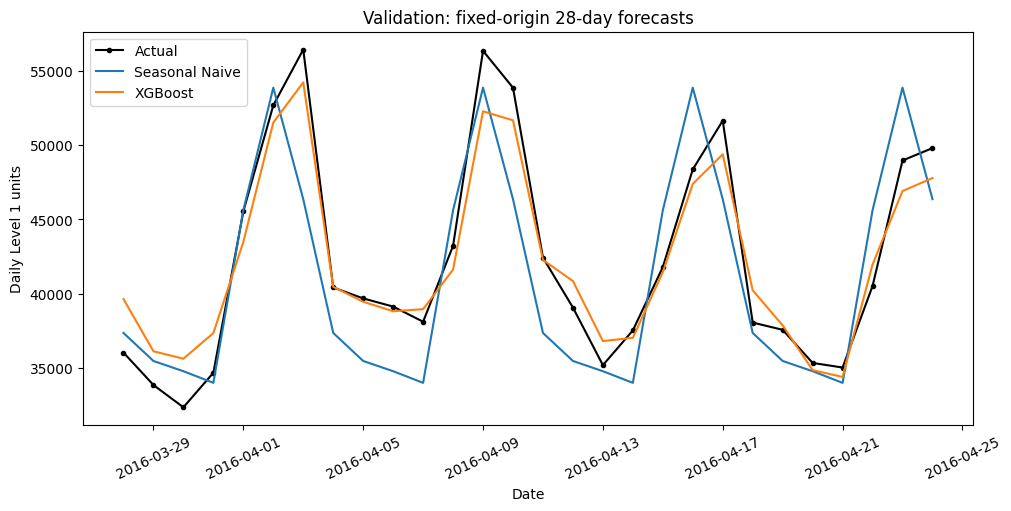

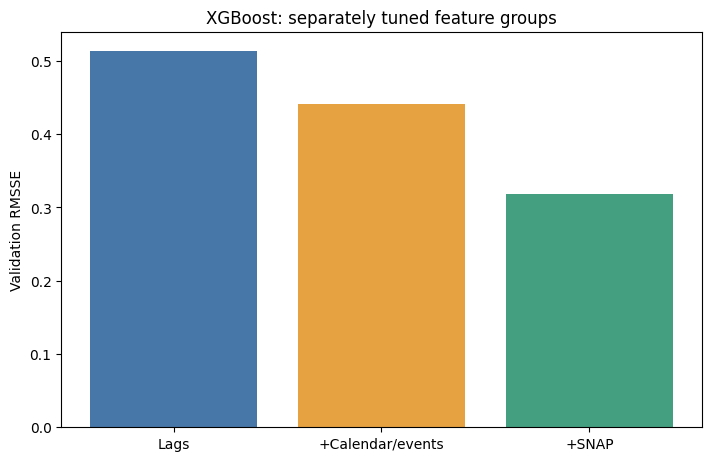

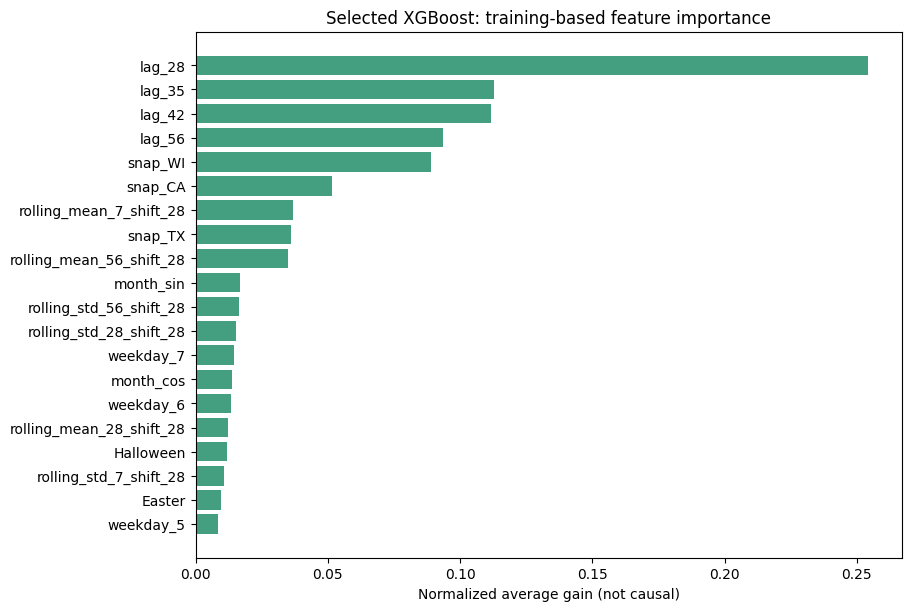

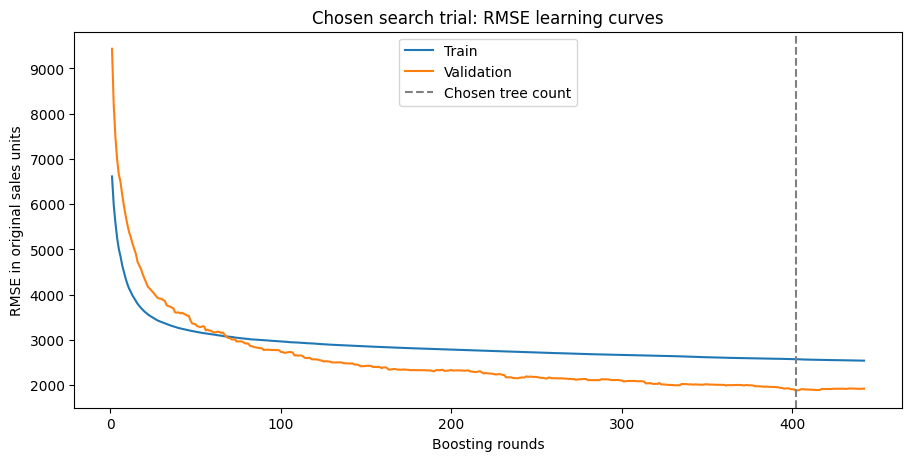

In [11]:
importance_rows, curve_rows = [], []
for group in FEATURE_GROUPS:
    if group not in refit_models:
        continue
    booster = refit_models[group].get_booster()
    gain, weight, total_gain = [booster.get_score(importance_type=kind) for kind in ['gain', 'weight', 'total_gain']]
    denominator = sum(gain.values())
    for name in bundles[3]['schema']['groups'][group]:
        importance_rows.append({'feature_group': group, 'feature': name,
            'display_name': bundles[3]['schema']['event_column_mapping'].get(name, name),
            'objective': group_winners[group]['objective'], 'gain': float(gain.get(name, 0)),
            'split_count': int(weight.get(name, 0)), 'total_gain': float(total_gain.get(name, 0)),
            'normalized_gain': float(gain.get(name, 0) / denominator) if denominator else 0.0,
            'selected_group': group == selected_group})
    curve = best_trial_curves[group]
    for iteration, (train_rmse, val_rmse) in enumerate(zip(curve['validation_0']['rmse'], curve['validation_1']['rmse'])):
        curve_rows.append({'feature_group': group, 'config_id': group_winners[group]['config_id'],
                          'iteration': iteration, 'train_rmse': train_rmse * SALES_SCALE,
                          'validation_rmse': val_rmse * SALES_SCALE,
                          'best_iteration': int(group_winners[group]['best_iteration'])})
feature_importance = pd.DataFrame(importance_rows)
learning_curves = pd.DataFrame(curve_rows)

fig_forecast, ax = plt.subplots(figsize=(10, 5), layout='constrained')
target = development.iloc[1885:1913]
ax.plot(target['date'], target['total_sales'], color='black', marker='o', markersize=3, label='Actual')
for cid in ['seasonal_naive_7', selected_config['config_id']]:
    p = cv_predictions[cv_predictions['config_id'].eq(cid) & cv_predictions['fold'].eq(3)]
    ax.plot(pd.to_datetime(p['date']), p['prediction'], label='Seasonal Naive' if cid == 'seasonal_naive_7' else 'XGBoost')
ax.set(title='Validation: fixed-origin 28-day forecasts', ylabel='Daily Level 1 units', xlabel='Date')
ax.legend(); ax.tick_params(axis='x', rotation=25)
plt.show()

fig_groups, ax = plt.subplots(figsize=(7, 4.5), layout='constrained')
rows = ablation_summary.set_index('feature_group').loc[list(FEATURE_GROUPS)]
ax.bar(range(3), rows['validation_rmsse'], color=['#4776a8', '#e6a141', '#439f80'])
ax.set_xticks(range(3), ['Lags', '+Calendar/events', '+SNAP'])
ax.set(title='XGBoost: separately tuned feature groups', ylabel='Validation RMSSE')
plt.show()

fig_importance, ax = plt.subplots(figsize=(9, 6), layout='constrained')
top = feature_importance[feature_importance['selected_group']].nlargest(20, 'normalized_gain').sort_values('normalized_gain')
ax.barh(top['display_name'], top['normalized_gain'], color='#439f80')
ax.set(title='Selected XGBoost: training-based feature importance', xlabel='Normalized average gain (not causal)')
plt.show()

fig_curve, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
curve = learning_curves[learning_curves['feature_group'].eq(selected_group)]
ax.plot(curve['iteration'] + 1, curve['train_rmse'], label='Train')
ax.plot(curve['iteration'] + 1, curve['validation_rmse'], label='Validation')
ax.axvline(int(selected_config['best_tree_count']), linestyle='--', color='grey', label='Chosen tree count')
ax.set(title='Chosen search trial: RMSE learning curves', xlabel='Boosting rounds', ylabel='RMSE in original sales units')
ax.legend()
plt.show()

## 5. Export portable models and the complete selection evidence

Save the three fixed-count Validation-origin group models in XGBoost's native
UBJSON format. Ordered input columns, feature schemas, model parameters, target
unit divisor and tree counts are stored separately in JSON. Model parameters
not represented by the trees must not be inferred from the model file alone.
The Optuna export includes all trial parameters, distributions, states and values.

Native model files and full prediction CSVs belong on Drive only. Result tables,
figures and JSON metadata may also be archived in GitHub after run verification.

In [12]:
artifact_dir = output_dir / '04_Outputs_and_Artifacts'
table_dir, figure_dir = artifact_dir / 'table', artifact_dir / 'figures'
model_dir = artifact_dir / 'models_saved' / 'xgboost'
prediction_dir = output_dir / '02_Data' / 'predictions'
for directory in [table_dir, figure_dir, model_dir, prediction_dir]:
    directory.mkdir(parents=True, exist_ok=True)
versions = {name: metadata.version(name) for name in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'optuna', 'matplotlib', 'threadpoolctl']}
versions['xgboost'] = xgb.__version__
exported_paths, model_records = [], []
for group, model in refit_models.items():
    winner = group_winners[group]
    _, F, names = matrices(3, group)
    path = model_dir / (winner['config_id'] + '.ubj')
    model.save_model(path)
    restored = xgb.XGBRegressor(n_jobs=1, device='cpu')
    restored.load_model(path)
    expected = np.asarray(model.predict(F), dtype=float) * SALES_SCALE
    require(np.allclose(np.asarray(restored.predict(F), dtype=float) * SALES_SCALE, expected,
                        rtol=1e-12, atol=1e-8), 'Native model round-trip changed forecasts.')
    model_records.append({'feature_group': group, 'config_id': winner['config_id'],
        'params': json.loads(winner['params_json']), 'tree_count': int(winner['best_tree_count']),
        'base_score': float(bundles[3]['y_train'].mean() / SALES_SCALE),
        'feature_names': names, 'selected_group': group == selected_group,
        'path': path.relative_to(output_dir).as_posix(),
        'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
    exported_paths.append(path)
tables = {'xgb_trial_search.csv': trial_results, 'xgb_fit_log.csv': fit_log,
          'xgb_cv_scores.csv': cv_scores, 'xgb_ablation_summary.csv': ablation_summary,
          'xgb_comparison_summary.csv': comparison_summary, 'xgb_feature_importance.csv': feature_importance,
          'xgb_learning_curves.csv': learning_curves, 'xgb_feature_inventory.csv': feature_dictionary,
          'xgb_feature_checks.csv': leakage_checks}
for name, frame in tables.items():
    path = table_dir / name; frame.to_csv(path, index=False); exported_paths.append(path)
for name, frame in [('xgb_trial_predictions.csv', trial_predictions), ('xgb_cv_predictions.csv', cv_predictions)]:
    path = prediction_dir / name; frame.to_csv(path, index=False); exported_paths.append(path)
for name, figure in [('xgb_validation_forecasts.png', fig_forecast), ('xgb_feature_groups.png', fig_groups),
                      ('xgb_feature_importance.png', fig_importance), ('xgb_learning_curve.png', fig_curve)]:
    path = figure_dir / name; figure.savefig(path, dpi=300); exported_paths.append(path)
study_export = {}
for group, study in studies.items():
    study_export[group] = {'direction': 'minimize', 'sampler': 'TPESampler', 'seed': SEED,
        'startup_trials': STARTUP_TRIALS, 'best_trial': study.best_trial.number,
        'trials': [{'number': t.number, 'state': t.state.name, 'value': t.value,
                    'params': t.params, 'user_attrs': t.user_attrs,
                    'distributions': {k: json.loads(optuna.distributions.distribution_to_json(v)) for k, v in t.distributions.items()}}
                   for t in study.get_trials(deepcopy=False)]}
study_path = artifact_dir / 'xgb_optuna_trials.json'
study_path.write_text(json.dumps(study_export, indent=2), encoding='utf-8'); exported_paths.append(study_path)
manifest = {
    'schema_version': 1, 'seed': SEED, 'horizon': HORIZON, 'origins': list(ORIGINS),
    'feature_algorithm_sha256': FEATURE_ALGORITHM_SHA256,
    'feature_schemas': {str(f): bundles[f]['schema'] for f in bundles},
    'target_divisor': SALES_SCALE, 'models': model_records, 'selected_group': selected_group,
    'selected_config_id': selected_config['config_id'], 'versions': versions,
    'search_protocol': {'trials_per_group': TRIALS_PER_GROUP, 'sampler': 'TPE', 'startup_trials': STARTUP_TRIALS,
                        'max_boost_rounds': MAX_BOOST_ROUNDS, 'early_stopping_rounds': EARLY_STOPPING_ROUNDS,
                        'eval_metric': 'RMSE before clipping', 'selection_metric': 'RMSSE after clipping',
                        'fixed_tree_refits': 'all origins, no eval_set; no early stopping on earlier holdouts'},
    'group_comparison': 'same trial budget; objectives/parameters/tree counts retuned per group',
    'stability_scope': 'retrospective development windows, including the selection window',
    'test_labels_read': False, 'test_forecasts_computed': False,
}
manifest_path = artifact_dir / 'xgb_selected_configurations.json'
manifest_path.write_text(json.dumps(manifest, indent=2), encoding='utf-8'); exported_paths.append(manifest_path)
report = {
    'status': 'PASS', 'created_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'versions': versions,
    'files_read': ['train.csv', 'val.csv'], 'test_labels_read': False, 'test_forecasts_computed': False,
    'data_fingerprints': {row['file']: row['table_sha256'] for row in input_inventory},
    'trial_count': len(trial_results), 'eligible_trials': int(trial_results['eligible'].sum()),
    'fit_count': len(fit_log), 'excluded_fits': int((~fit_log['eligible']).sum()),
    'cv_score_rows': len(cv_scores), 'cv_forecast_rows': len(cv_predictions),
    'trial_forecast_rows': len(trial_predictions), 'saved_models': len(model_records),
    'feature_checks': int(leakage_checks['passed'].sum()),
    'trial_cap_hits': int(trial_results['hit_round_cap'].sum()),
    'cv_clipped_forecasts': int(cv_scores['clipped_forecasts'].sum()),
    'selected_group': selected_group, 'main_comparison': comparison_summary.to_dict('records'),
    'ablation': ablation_summary.to_dict('records'),
    'elapsed_seconds_before_packaging': perf_counter() - RUN_STARTED,
    'files': [path.relative_to(output_dir).as_posix() for path in exported_paths],
}
report_path = artifact_dir / 'xgb_run_report.json'
report_path.write_text(json.dumps(report, indent=2), encoding='utf-8'); exported_paths.append(report_path)
zip_path = output_dir / '07_xgboost_results.zip'
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as archive:
    for path in exported_paths:
        archive.write(path, path.relative_to(output_dir).as_posix())
with ZipFile(zip_path) as archive:
    require(archive.testzip() is None and len(archive.namelist()) == len(exported_paths), 'Incomplete archive.')
print('XGBOOST CHECK PASSED')
print(f'Optuna trials: {len(trial_results)}; fits: {len(fit_log)}; excluded: {int((~fit_log["eligible"]).sum())}')
print(f'Folds: 3; comparison models: {len(comparison_summary)}; saved models: {len(model_records)}')
print(f'CV forecast rows: {len(cv_predictions)}; feature checks: 24/24')
print(f'Download: {zip_path}')

XGBOOST CHECK PASSED
Optuna trials: 72; fits: 81; excluded: 0
Folds: 3; comparison models: 5; saved models: 3
CV forecast rows: 588; feature checks: 24/24
Download: /kaggle/working/07_xgboost_results.zip


## Interpretation and references

The bounded search does not prove global parameter optimality. A cap hit records
a finite search budget, not automatic convergence or failure. Objective and
group selection are Validation decisions; Test remains outside this notebook.
Training-based importance is descriptive of fitted trees, not evidence of a
SNAP policy effect. Previous model families remain audited inputs for the later
consolidated benchmark.

Official sources: [XGBoost Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html),
[early-stopping prediction behavior](https://xgboost.readthedocs.io/en/stable/prediction.html),
[model IO](https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html),
[Optuna TPE](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html).